In [3]:
pip install pandas numpy matplotlib seaborn statsmodels plotly openpyxl

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.4 MB 524.3 kB/s eta 0:00:21
   -- ------------------------------------- 0.8/11.4 MB 685.3 kB/s eta 0:00:16
   -- ------------------------------------- 0.8/11.4 MB 685.3 kB/s eta 0:00:16
   -- ------------------------------------- 0.8/11.4 MB 685.3 kB/s eta 0:00:16
   -- ------------------------------------- 0.8/11.4 MB 685.3 kB/s eta 0:00:16
   -- ------------------------------------- 0.8/11.4 MB 685.3 kB/s eta 0:00:16
   --- -----------------------------

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import statsmodels.api as sm
from statsmodels.tsa.ardl import ARDL
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")

# 1. 读取 FRED 违约率数据 (全国季度)
delinq = pd.read_csv('DRCCLACBS.csv')
delinq['observation_date'] = pd.to_datetime(delinq['observation_date'])
delinq['Quarter'] = delinq['observation_date'].dt.to_period('Q')
delinq = delinq[['Quarter', 'DRCCLACBS']].rename(columns={'DRCCLACBS': 'delinq_rate'})

# 2. 读取 BLS 失业率数据 (州级月度)
try:
    bls_raw = pd.read_excel('SeriesReport-20261019050857_3cedaf.xlsx', skiprows=3)
except Exception as e:
    print("读取失败，尝试其他跳过行数...")
    bls_raw = pd.read_excel('SeriesReport-20261019050857_3cedaf.xlsx', skiprows=4)

bls_raw.rename(columns={bls_raw.columns[0]: 'Series ID'}, inplace=True)

# 清理列名中的换行符
bls_raw.columns = [str(c).replace('<br>', ' ') for c in bls_raw.columns]

# 宽表转长表
bls_long = pd.melt(bls_raw, id_vars=['Series ID'], var_name='Date_Str', value_name='unemp_rate')
bls_long = bls_long.dropna(subset=['unemp_rate'])
bls_long['unemp_rate'] = pd.to_numeric(bls_long['unemp_rate'], errors='coerce')

# 提取州 FIPS 代码
bls_long['State_FIPS'] = bls_long['Series ID'].astype(str).str[5:7]

# 转换日期为季度
bls_long['Date'] = pd.to_datetime(bls_long['Date_Str'], format='%b %Y', errors='coerce')
bls_long = bls_long.dropna(subset=['Date']) # 
bls_long['Quarter'] = bls_long['Date'].dt.to_period('Q')

# 过滤 2000 - 2025 年的数据
bls_long = bls_long[(bls_long['Date'].dt.year >= 2000) & (bls_long['Date'].dt.year <= 2025)]

# 聚合到州-季度层面
state_quarter_unemp = bls_long.groupby(['State_FIPS', 'Quarter'])['unemp_rate'].mean().reset_index()

# 建立 FIPS 到州简称的映射
fips_to_state = {
    '01':'AL','02':'AK','04':'AZ','05':'AR','06':'CA','08':'CO','09':'CT','10':'DE','11':'DC',
    '12':'FL','13':'GA','15':'HI','16':'ID','17':'IL','18':'IN','19':'IA','20':'KS','21':'KY',
    '22':'LA','23':'ME','24':'MD','25':'MA','26':'MI','27':'MN','28':'MS','29':'MO','30':'MT',
    '31':'NE','32':'NV','33':'NH','34':'NJ','35':'NM','36':'NY','37':'NC','38':'ND','39':'OH',
    '40':'OK','41':'OR','42':'PA','44':'RI','45':'SC','46':'SD','47':'TN','48':'TX','49':'UT',
    '50':'VT','51':'VA','53':'WA','54':'WV','55':'WI','56':'WY'
}
state_quarter_unemp['State'] = state_quarter_unemp['State_FIPS'].map(fips_to_state)

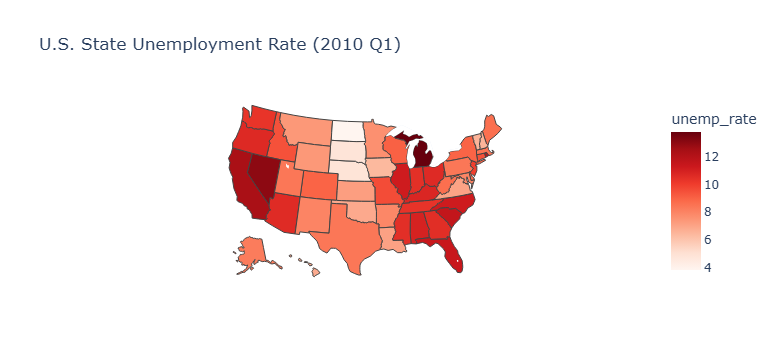

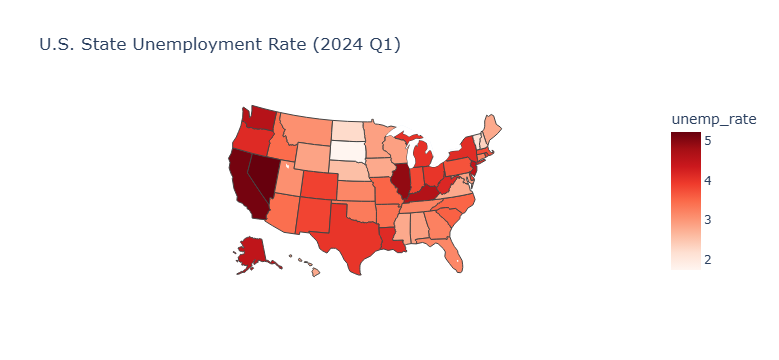

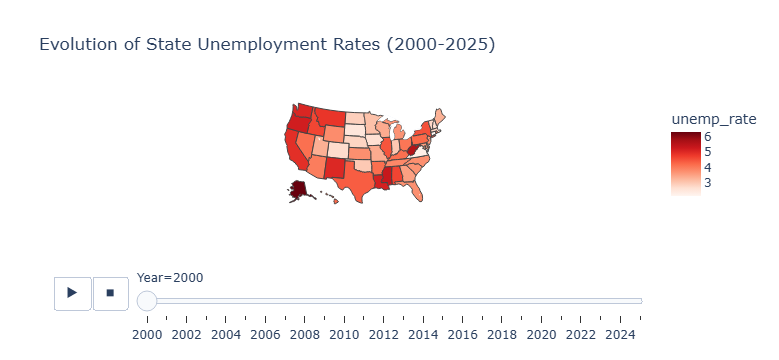

In [53]:
# 提取 2010 年 Q1 和 2024 年 Q1 的数据作为对比
df_2010 = state_quarter_unemp[state_quarter_unemp['Quarter'] == '2010Q1']
df_2024 = state_quarter_unemp[state_quarter_unemp['Quarter'] == '2024Q1']

# 1. 2010 Q1 地图
fig1 = px.choropleth(df_2010, locations='State', locationmode="USA-states", color='unemp_rate',
                     scope="usa", color_continuous_scale="Reds", title="U.S. State Unemployment Rate (2010 Q1)")
fig1.show()

# 2. 2024 Q1 地图
fig2 = px.choropleth(df_2024, locations='State', locationmode="USA-states", color='unemp_rate',
                     scope="usa", color_continuous_scale="Reds", title="U.S. State Unemployment Rate (2024 Q1)")
fig2.show()

# 3. 动态地图 
state_quarter_unemp['Year'] = state_quarter_unemp['Quarter'].astype(str).str[:4]
df_annual = state_quarter_unemp.groupby(['State', 'Year'])['unemp_rate'].mean().reset_index()
fig_anim = px.choropleth(df_annual, locations='State', locationmode="USA-states", color='unemp_rate',
                         animation_frame="Year", scope="usa", color_continuous_scale="Reds",
                         title="Evolution of State Unemployment Rates (2000-2025)")
fig_anim.show() #

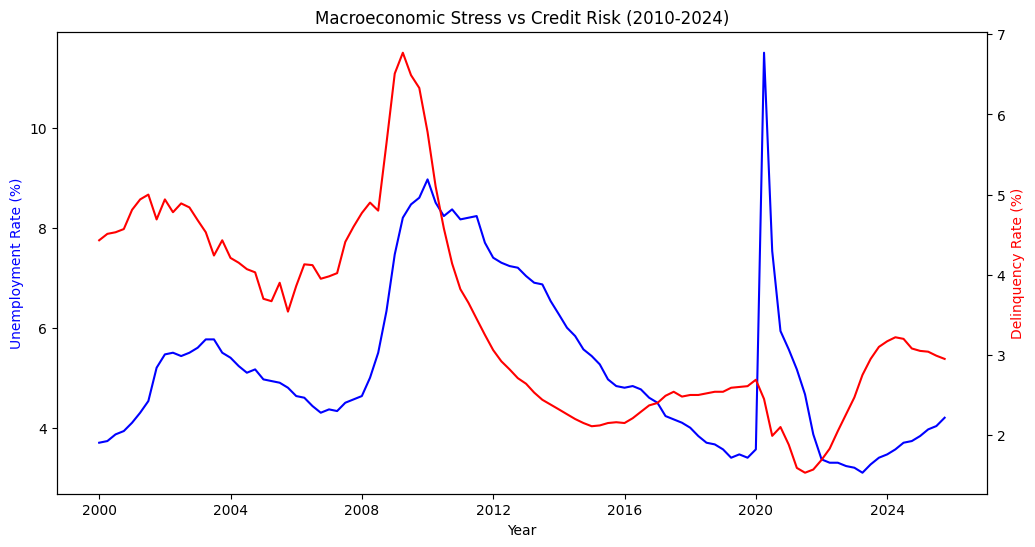

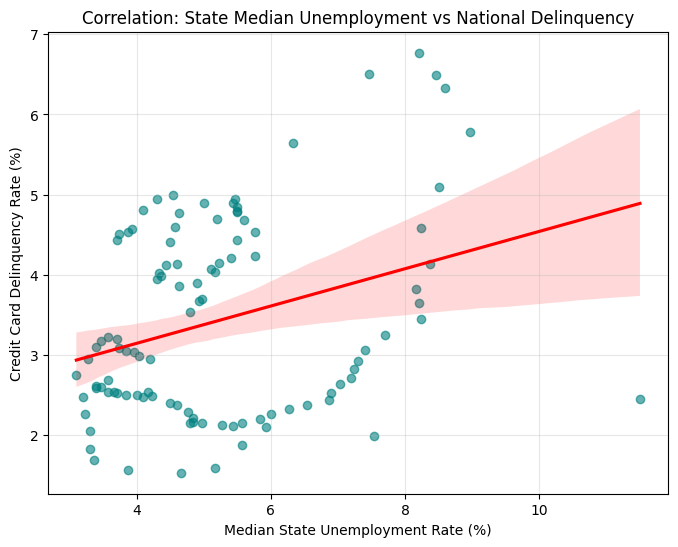

In [31]:
# 计算每季度的截面统计量
exposure = state_quarter_unemp.groupby('Quarter')['unemp_rate'].agg(
    median_unemp='median',
    iqr_unemp=lambda x: x.quantile(0.75) - x.quantile(0.25)
).reset_index()

# 合并全国违约率
df = pd.merge(exposure, delinq, on='Quarter', how='inner')
df = df.sort_values('Quarter').set_index('Quarter')

# COVID 虚拟变量 (2020 Q2 - Q4)
df['covid_dummy'] = 0
df.loc['2020Q2':'2020Q4', 'covid_dummy'] = 1

# --- 图表：时间趋势 ---
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()
ax1.plot(df.index.to_timestamp(), df['median_unemp'], color='blue', label='Median State Unemployment')
ax2.plot(df.index.to_timestamp(), df['delinq_rate'], color='red', label='National Delinquency Rate')
ax1.set_xlabel('Year')
ax1.set_ylabel('Unemployment Rate (%)', color='blue')
ax2.set_ylabel('Delinquency Rate (%)', color='red')
plt.title('Macroeconomic Stress vs Credit Risk (2010-2024)')
plt.show()

# --- 图表：散点图 + 线性拟合 + 95% 置信带 ---
plt.figure(figsize=(8, 6))
sns.regplot(data=df, x='median_unemp', y='delinq_rate', 
            scatter_kws={'alpha':0.6, 'color':'teal'}, line_kws={'color':'red'})
plt.title('Correlation: State Median Unemployment vs National Delinquency')
plt.xlabel('Median State Unemployment Rate (%)')
plt.ylabel('Credit Card Delinquency Rate (%)')
plt.grid(True, alpha=0.3)
plt.show()



In [55]:

import statsmodels.formula.api as smf

# 1. 读取并清洗 BEA 消费支出数据 
bea = pd.read_csv('Table.csv', skiprows=3)

# 过滤掉大区数据 (只保留 50 州 + DC)
bea_states = bea[bea['GeoFIPS'].astype(str).str.endswith('000')]
bea_states = bea_states[~bea_states['GeoFIPS'].astype(str).str.startswith('9')]
bea_states = bea_states[bea_states['GeoFIPS'] != '00000']

# 提取 2000-2025 年的列
year_cols = [str(y) for y in range(2000, 2025)]
bea_states = bea_states[['GeoName'] + year_cols]

# 宽表转长表
bea_long = pd.melt(bea_states, id_vars=['GeoName'], var_name='Year', value_name='PCE')
bea_long['Year'] = bea_long['Year'].astype(int)
bea_long['PCE'] = pd.to_numeric(bea_long['PCE'], errors='coerce')

# 2. 计算全国总 PCE 及其年度增长率
# "失业率 -> 消费降低"，将所有州的 PCE 加总得到全国 PCE
national_pce = bea_long.groupby('Year')['PCE'].sum().reset_index()
# 计算年增长率 (%)：当年 / 去年 - 1
national_pce['PCE_growth'] = national_pce['PCE'].pct_change() * 100
national_pce = national_pce.dropna()

# 3. 将季度指标降维到年度（求均值）
# df 是我们前面生成的季度 DataFrame
df['Year'] = df.index.year
annual_unemp = df.groupby('Year')['median_unemp'].mean().reset_index()

# 4. 合并年度数据
annual_df = pd.merge(annual_unemp, national_pce, on='Year', how='inner')
print("合并后的年度面板数据：\n", annual_df)

# 5. 回归分析：PCE 增长率 ~ 中位数失业率
pce_model = smf.ols('PCE_growth ~ median_unemp', data=annual_df).fit()
print("\n--- 消费支出回归结果 ---")
print(pce_model.summary())

# 使用稳健标准误 (HC3) 的 OLS 模型
pce_model_robust = smf.ols('PCE_growth ~ median_unemp', data=annual_df).fit(cov_type='HC3')

print("\n--- 消费支出回归结果 (Robust SE) ---")
print(pce_model_robust.summary())



合并后的年度面板数据：
     Year  median_unemp         PCE  PCE_growth
0   2001      4.533333   7070043.0    4.530129
1   2002      5.475000   7344682.4    3.884551
2   2003      5.658333   7735298.6    5.318354
3   2004      5.225000   8226123.4    6.345260
4   2005      4.900000   8763125.9    6.528014
5   2006      4.491667   9270838.3    5.793736
6   2007      4.441667   9739296.4    5.053028
7   2008      5.366667  10042166.2    3.109771
8   2009      8.183333   9882222.0   -1.592726
9   2010      8.516667  10251885.2    3.740689
10  2011      8.075000  10689259.1    4.266278
11  2012      7.283333  11038476.0    3.266989
12  2013      6.833333  11379914.1    3.093163
13  2014      5.916667  11866076.2    4.272107
14  2015      5.125000  12290123.8    3.573613
15  2016      4.750000  12719817.1    3.496249
16  2017      4.250000  13283618.7    4.432466
17  2018      3.800000  13923981.3    4.820694
18  2019      3.458333  14426092.2    3.606087
19  2020      7.133333  14220226.9   -1.427034


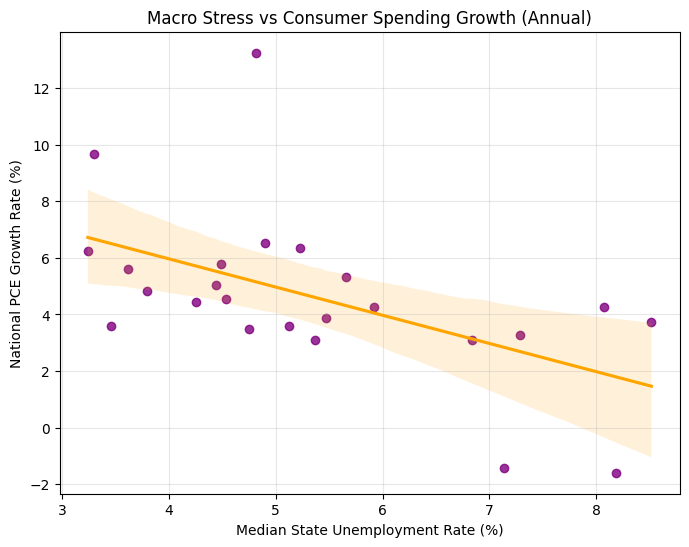

In [57]:
# 6. 可视化：失业率 vs 消费增长率 散点图
plt.figure(figsize=(8, 6))
sns.regplot(data=annual_df, x='median_unemp', y='PCE_growth', 
            scatter_kws={'alpha':0.8, 'color':'purple'}, line_kws={'color':'orange'})
plt.title('Macro Stress vs Consumer Spending Growth (Annual)')
plt.xlabel('Median State Unemployment Rate (%)')
plt.ylabel('National PCE Growth Rate (%)')
plt.grid(True, alpha=0.3)
plt.show()

  State State_FIPS     GeoName  Year       PCE
0    AL         01     Alabama  2000   89748.7
1    AK         02      Alaska  2000   17107.7
2    AZ         04     Arizona  2000  121418.9
3    AR         05    Arkansas  2000   50566.1
4    CA         06  California  2000  844374.3
州数： 51  年份数： 26


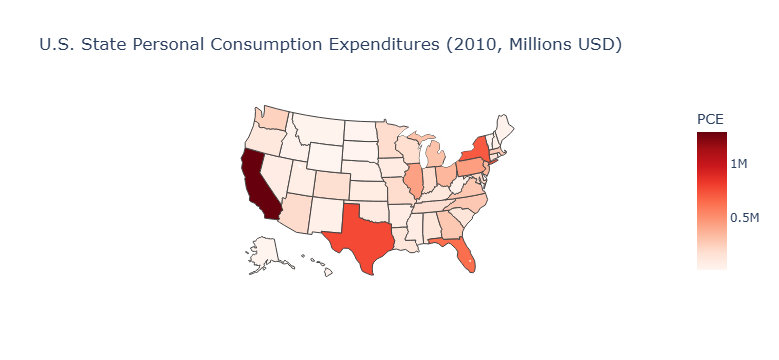

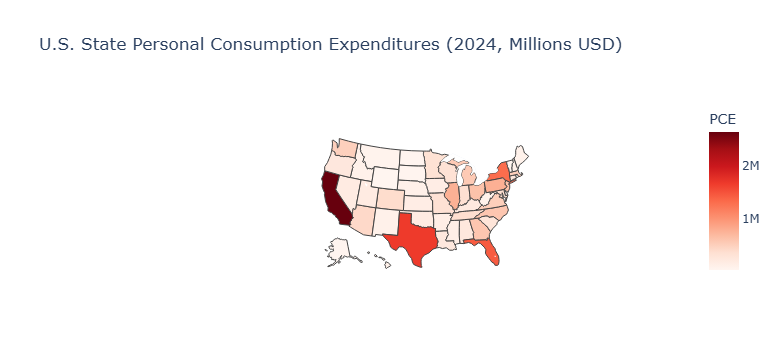

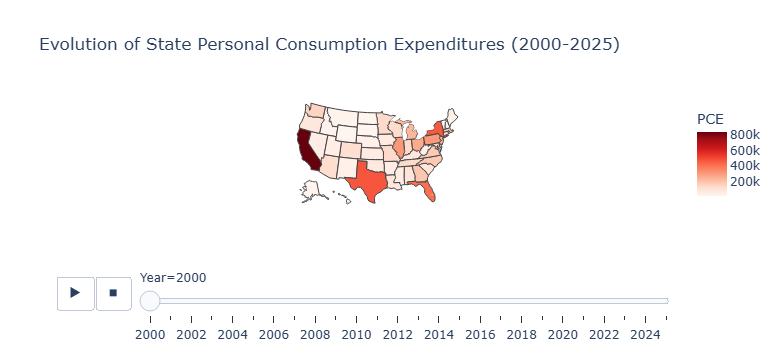

In [59]:
# =========================================================
# 州级消费（PCE）地图 —— 
# =========================================================

# 1. 读取并清洗 BEA 消费支出数据 (Table.csv)
bea = pd.read_csv('Table.csv', skiprows=3, dtype={'GeoFIPS': str})
bea['GeoFIPS'] = bea['GeoFIPS'].astype(str).str.zfill(5)   # '1000' -> '01000'

# 过滤掉大区数据（只保留 50 州 + DC）
bea_states = bea[bea['GeoFIPS'].str.endswith('000')]
bea_states = bea_states[~bea_states['GeoFIPS'].str.startswith('9')]
bea_states = bea_states[bea_states['GeoFIPS'] != '00000']

# 提取 2000-2025 年的列（与失业率地图的时间范围一致）
year_cols = [str(y) for y in range(2000, 2026)]
bea_states = bea_states[['GeoFIPS', 'GeoName'] + year_cols]

# 宽表转长表
pce_long = pd.melt(bea_states,
                   id_vars=['GeoFIPS', 'GeoName'],
                   value_vars=year_cols,
                   var_name='Year', value_name='PCE')
pce_long['Year'] = pce_long['Year'].astype(int)
pce_long['PCE']  = pd.to_numeric(pce_long['PCE'], errors='coerce')

# 提取州 FIPS 并映射
pce_long['State_FIPS'] = pce_long['GeoFIPS'].str[:2]
pce_long['State']      = pce_long['State_FIPS'].map(fips_to_state)
pce_long = pce_long.dropna(subset=['State'])

state_year_pce = pce_long[['State', 'State_FIPS', 'GeoName', 'Year', 'PCE']].reset_index(drop=True)
print(state_year_pce.head())
print("州数：", state_year_pce['State'].nunique(), " 年份数：", state_year_pce['Year'].nunique())

# =========================================================
# 2. 提取 2010 年和 2024 年的数据作为对比
# =========================================================
df_pce_2010 = state_year_pce[state_year_pce['Year'] == 2010]
df_pce_2024 = state_year_pce[state_year_pce['Year'] == 2024]

# 3. 2010 年消费地图
fig_pce_2010 = px.choropleth(
    df_pce_2010,
    locations='State', locationmode="USA-states",
    color='PCE',
    scope="usa",
    color_continuous_scale="Reds",
    title="U.S. State Personal Consumption Expenditures (2010, Millions USD)"
)
fig_pce_2010.show()

# 4. 2024 年消费地图
fig_pce_2024 = px.choropleth(
    df_pce_2024,
    locations='State', locationmode="USA-states",
    color='PCE',
    scope="usa",
    color_continuous_scale="Reds",
    title="U.S. State Personal Consumption Expenditures (2024, Millions USD)"
)
fig_pce_2024.show()

# 5. 动态地图（按年）
fig_pce_anim = px.choropleth(
    state_year_pce,
    locations='State', locationmode="USA-states",
    color='PCE',
    animation_frame='Year',
    scope="usa",
    color_continuous_scale="Reds",
    title="Evolution of State Personal Consumption Expenditures (2000-2025)"
)
fig_pce_anim.show()

    State State_FIPS GeoName  Year      PCE  PCE_growth
52     AK         02  Alaska  2001  18123.5    5.937677
103    AK         02  Alaska  2002  19432.2    7.221011
154    AK         02  Alaska  2003  20557.2    5.789360
205    AK         02  Alaska  2004  21847.5    6.276633
256    AK         02  Alaska  2005  23354.8    6.899188
Growth year range: 2001 - 2025


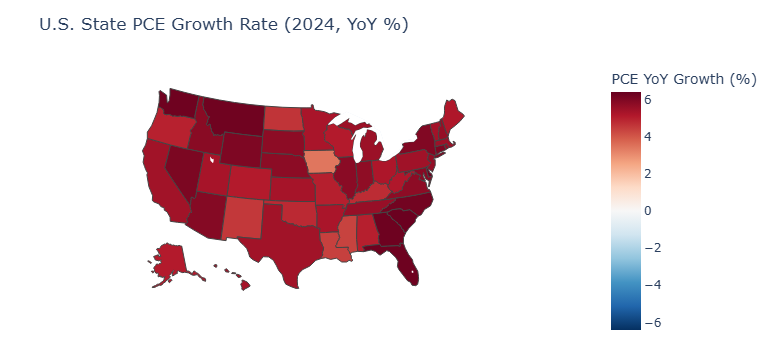

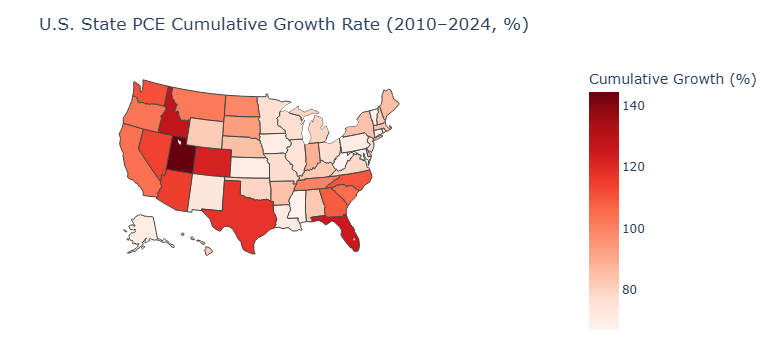

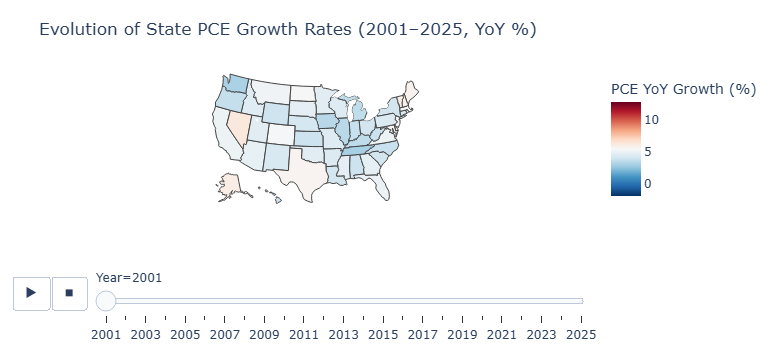

In [63]:
# =========================================================

pce_sorted = state_year_pce.sort_values(['State', 'Year']).copy()
pce_sorted['PCE_growth'] = (
    pce_sorted.groupby('State')['PCE']
    .pct_change(fill_method=None) * 100
)

pce_growth_long = pce_sorted.dropna(subset=['PCE_growth']).copy()

print(pce_growth_long.head())
print("Growth year range:", pce_growth_long['Year'].min(), "-", pce_growth_long['Year'].max())


# =========================================================
df_growth_2024 = pce_growth_long[pce_growth_long['Year'] == 2024]

fig_growth_2024 = px.choropleth(
    df_growth_2024,
    locations='State',
    locationmode="USA-states",
    color='PCE_growth',
    scope="usa",
    color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0,
    hover_name='GeoName',
    labels={'PCE_growth': 'PCE YoY Growth (%)'},
    title="U.S. State PCE Growth Rate (2024, YoY %)"
)
fig_growth_2024.update_layout(
    coloraxis_colorbar=dict(title="PCE YoY Growth (%)"),
    margin=dict(l=20, r=20, t=60, b=20)
)
fig_growth_2024.show()


# =========================================================
pivot_pce = state_year_pce.pivot(index='State', columns='Year', values='PCE')

growth_df = pd.DataFrame({
    'State': pivot_pce.index,
    'growth_pct': (pivot_pce[2024] / pivot_pce[2010] - 1) * 100
}).reset_index(drop=True)

state_name_map = (
    state_year_pce.drop_duplicates('State')
    .set_index('State')['GeoName']
)
growth_df['GeoName'] = growth_df['State'].map(state_name_map)

fig_growth_cum = px.choropleth(
    growth_df,
    locations='State',
    locationmode="USA-states",
    color='growth_pct',
    scope="usa",
    color_continuous_scale="Reds",
    hover_name='GeoName',
    labels={'growth_pct': 'Cumulative Growth 2010–2024 (%)'},
    title="U.S. State PCE Cumulative Growth Rate (2010–2024, %)"
)
fig_growth_cum.update_layout(
    coloraxis_colorbar=dict(title="Cumulative Growth (%)"),
    margin=dict(l=20, r=20, t=60, b=20)
)
fig_growth_cum.show()

# =========================================================

growth_min = pce_growth_long['PCE_growth'].quantile(0.02)
growth_max = pce_growth_long['PCE_growth'].quantile(0.98)

fig_growth_anim = px.choropleth(
    pce_growth_long,
    locations='State',
    locationmode="USA-states",
    color='PCE_growth',
    animation_frame='Year',
    scope="usa",
    color_continuous_scale="RdBu_r",
    color_continuous_midpoint=0,
    range_color=[growth_min, growth_max],
    hover_name='GeoName',
    labels={'PCE_growth': 'PCE YoY Growth (%)'},
    title="Evolution of State PCE Growth Rates (2001–2025, YoY %)"
)
fig_growth_anim.update_layout(
    coloraxis_colorbar=dict(title="PCE YoY Growth (%)"),
    margin=dict(l=20, r=20, t=70, b=20)
)
fig_growth_anim.show()